# Hit-Generation by Fragment-Based Molecular Optimization

In [1]:
#!pip install pyTDC

In [2]:
#!pip install safe-mol datamol pandas numpy rdkit msal 2>/dev/null | tail -n 1

In [3]:
#!pip install msal

In [1]:
from nv_genmol.optimizer import MolecularOptimizer
from nv_genmol.library import Library
from nv_genmol.genmol import GenMol_Generator
from nv_genmol.oracle import Oracle

import pandas as pd
import safe as sf


## Library

#### Read molecular library of FDA-approved drugs with 20~30 heavy atoms 

In [2]:
mol_library = pd.read_csv('../../data/interim/genmol/BCS-CE65417_R1_testmulti.csv')
mol_library

,smiles,score
0,O=C(NCc1cccc(F)c1)C1CC([N+]Cl)=NO1,0.900
1,COC1=NOC(C(=O)NCc2cccc(I)c2)C1,0.835
2,O=C(Nc1[o+]cccc1O)C1CC(C(F)F)=NO1,0.808
3,COC(=O)c1ccc(C2=NOC(C(N)=O)C2)cc1,0.786
4,COCCC(=O)NC(=O)C1CC(C(C)C)=NO1,0.760
...,...,...
231,COC(=O)CCNNCCOc1cc(Cl)cc(Cl)c1,0.437
232,COC(=O)CCNOCCC(=O)Nc1cc(Cl)cc(Cl)c1,0.433
233,COC(=O)CCNOC[C@@H](O)COc1cc(Cl)cc(Cl)c1,0.406
234,COC(=O)CCN[N-]CC(=O)c1cc(Cl)cc(Cl)c1,0.364


In [3]:
m1 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
m1_name = "BCS-CE65417"

## calc score with the right scorer 

In [4]:
from nv_genmol.by_scorer_new import MoleculeScorer

hsec_scorer = MoleculeScorer.create_scorer( reference_smiles = m1,
                                            use_qsar_hsec=True,
                                            use_qsar_aih=False,
                                            use_qed = False,
                                            use_similarity=False,
                                            similarity_weight=1.0,
                                            similarity_threshold=1.0)

results = hsec_scorer.score(mol_library['smiles'])

#~now scoring~#
#~Done scoring~#


In [8]:
len(results.combined_scores)

236

**change the Scorer HERE if needed**

In [5]:
#drop original score column
mol_library.drop('score',axis=1,inplace=True)

#create new score column with QSAR scores
mol_library['score'] = results.qsar_hsec_scores # combined_scores / qsar_hsec_scores
mol_library.sort_values(by='score',ascending=False, inplace=True)
print(len(mol_library))
mol_library.head()

236


,smiles,score
146,COC(=O)CCNC(=O)C1(c2cc(Cl)cc(Cl)c2)[C]C=C[CH]1,102.85
66,CCn1cc(CNC(=O)Cc2ccc(Br)cc2S)c(C)n1,89.93
149,C=C(NCCC(=O)OC)c1cc(Cl)cc(Cl)c1,86.76
52,O=C1NCC2=NOC1C2,86.49
43,O=C1C=CCC2=NOC(C2)C(=O)N1,84.26


#### Initiate fragment library from known molecules

In [6]:
library = Library(max_fragments = 1000)

In [7]:
molecules = {r['smiles']:r['score'] for idx, r in mol_library.iterrows()}
library.update(molecules)

min score:0.0


In [8]:
#library.fragments
library.export(2)

['[B+]=C(C3)c1cc(Cl)cc(Cl)c1.C4CC2=O.N34.O2C',
 'Cc1nn(C5=O)cc16.C15CC=NO1.C3(=O)C[NH2+].C46.N34']

## Oracle

In [9]:
#oracle = Oracle(score = Oracle.RDKitScore('SA'))
# Create an Oracle with HSEC scoring
oracle = Oracle(score=Oracle.HSECScore('hsec', ref_smiles="COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1")) #hsec / comp

In [11]:
# test eval with the original seed 
oracle.evaluate([m1])

#~now scoring~#
#~Done scoring~#


{'CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1': 151.04}

## Generator

In [12]:
GENMOL_HOST = 'http://127.0.0.1:8083'
generator = GenMol_Generator(invoke_url = f"{GENMOL_HOST}/generate")

### Test generator

In [13]:
generator.inference(
    smiles = 'c13cc(Cl)cc(Cl)c1.[*{8-20}]',
    num_molecules = 5,
    temperature = 2.0, #1.5
    noise = 1.0 #2.0
)

[{'smiles': 'Clc1cc(Cl)cc(Nc2cc(Br)cnn2)c1', 'score': 0.897},
 {'smiles': '[NH-]c1cc(Cl)cc(Cl)c1', 'score': 0.554},
 {'smiles': 'Clc1cccc(Cl)c1', 'score': 0.529}]

In [14]:
generator.produce(['CCC1CCC1CC(=O)NCCC(=O)OC'], 1)

['Cc1cnc(C(N)c2ccccc2)o1']

## Optimizer

In [15]:
optimizer = MolecularOptimizer(library = library, oracle = oracle, generator = generator)

In [ ]:
data = []

In [17]:
steps=200

def eval():
    best = library.molecules.score[0]
    mean = library.molecules.head(50)['score'].mean()
    std = library.molecules.head(50)['score'].std()
    print("BEST", best, "MEAN", mean, "STD", std)
    data.append([best, mean, std])

eval()

for i in range(steps):
    optimizer.run(iterations = 10, num_mutate = 50)
    eval()

BEST 102.85 MEAN 71.2244 STD 7.951870825953665
#~now scoring~#
#~Done scoring~#
min score:18.68
#~now scoring~#
#~Done scoring~#
min score:20.16
#~now scoring~#
#~Done scoring~#
min score:20.6
#~now scoring~#
#~Done scoring~#
min score:20.6
#~now scoring~#
#~Done scoring~#
min score:20.91
#~now scoring~#
#~Done scoring~#
min score:21.15
#~now scoring~#
#~Done scoring~#
min score:21.34
#~now scoring~#
#~Done scoring~#
min score:21.81
#~now scoring~#
#~Done scoring~#
min score:21.81
#~now scoring~#
#~Done scoring~#
min score:22.01
BEST 102.85 MEAN 71.756 STD 8.240077768604678
#~now scoring~#
#~Done scoring~#
min score:22.01
#~now scoring~#
#~Done scoring~#
min score:22.01
#~now scoring~#
#~Done scoring~#
min score:22.12
#~now scoring~#
#~Done scoring~#
min score:22.12
#~now scoring~#
#~Done scoring~#
min score:22.59
#~now scoring~#
#~Done scoring~#
min score:22.64
#~now scoring~#
#~Done scoring~#
min score:22.64
#~now scoring~#
#~Done scoring~#
min score:22.64
#~now scoring~#
#~Done scor

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(data, columns = ['best', 'mean', 'std'])

plt.fill_between(df.index, df['mean']-df['std'], df['mean'] + df['std'], alpha=0.4)
plt.plot(df['mean'])
plt.plot(df['best'])

NameError: name 'data' is not defined

In [20]:
df.shape

NameError: name 'df' is not defined

# Outputs

In [21]:
df_safe = library.molecules
df_safe.head()

,smiles,score
0,[C]=C(C)NC(=O)c1cc(C)c(C2(C3CC4C=NC(=O)N(C(F)(...,179.10
1,CONC(=O)N[C@@H](COC(=O)C(F)(F)c1cc(Cl)cc(Cl)c1...,166.85
2,Nc1cc(N2C=CC2=O)cc(C(F)(F)C(=O)N2CC(NC(=O)c3cc...,140.42
3,[C]=C(C)NC(=O)c1cc(C)c(C2(C3CC4C=NC(=O)N(C(F)(...,140.33
4,C=C(C[O+](C)CCC1CC=NO1)N1C(=O)N=CC2CC(C3(F)CCO...,140.25


In [22]:
len(df_safe)

800

[C]=C(C)NC(=O)c1cc(C)c(C2(C3CC4C=NC(=O)N(C(F)(F)c5cc(N)cc(OC(=O)CCOCCC6CC=NO6)c5)C4C3=O)CCO2)cc1F


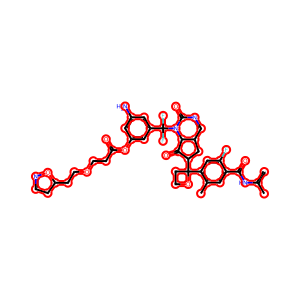

In [23]:
import safe as sf
print(df_safe.iloc[0,0])
sf.to_image(df_safe.iloc[0,0])


In [24]:
type(df_safe)

pandas.core.frame.DataFrame

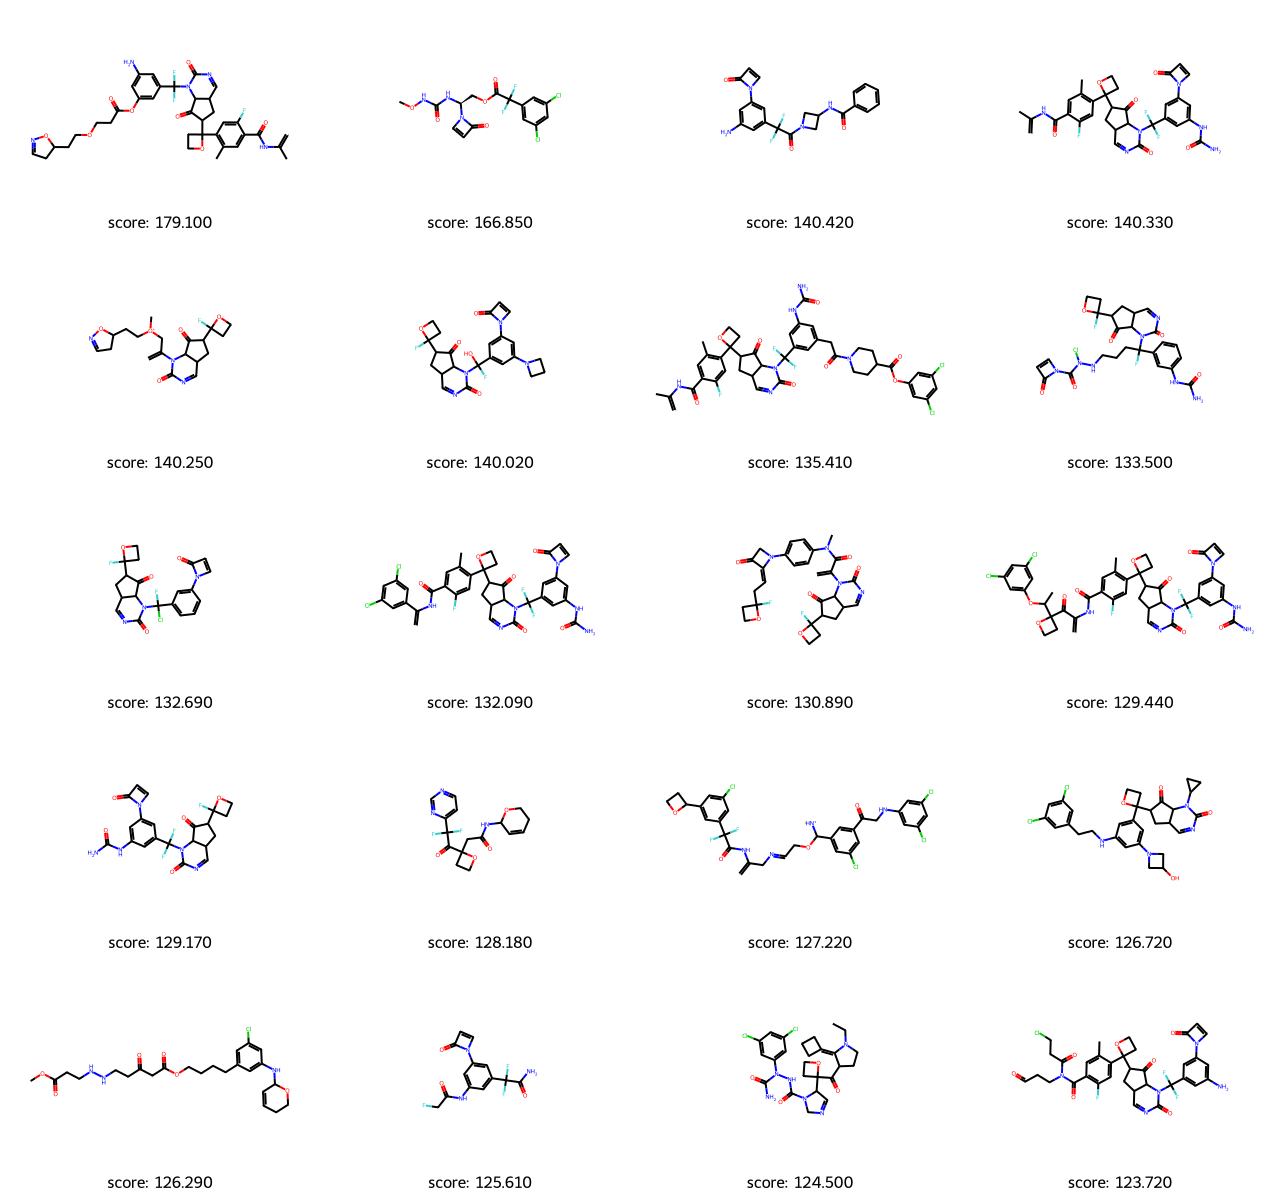

In [25]:
from rdkit.Chem import Draw
from rdkit import Chem
#select first 20
df_to_show = df_safe.iloc[0:20].copy()

#vis
ms = [Chem.MolFromSmiles(row['smiles']) for index, row in df_to_show.iterrows()]
legends = ['score: {:.3f}'.format(row['score']) for index, row in df_to_show.iterrows()]
#['score ' + str(row['score']) for index, row in df_to_show.iterrows()]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(320, 240), legends=legends)
